# Handwritten Digit Recognition — End-to-End Notebook

**Goal:** recognise a handwritten digit (0–9) that a user **draws in the browser**, using a neural network.

**What we build:**
1. neural networks that classify small 8×8 images of digits: a scikit-learn `MLPClassifier` (runs everywhere) and
   a Keras dense network + a small CNN (needs TensorFlow),
2. a **preprocessing function** that turns a big drawing from a web canvas into the same 8×8 format as the training
   images — this is the step that makes or breaks the app,
3. saved model files + `models/model_info.json` that the Flask API loads.

**Methods practised:** Batch 2 Module 05 (neural networks / ANN: layers, activations, softmax, loss, overfitting)
and Module 06 (TensorFlow/Keras: `Sequential`, `compile`, `fit`, `EarlyStopping`, saving `.keras` models, CNN layers).

**Expected result:** neural networks that are clearly better than a simple baseline on held-out test images,
plus an honest look at how the model behaves on *drawn* digits, which look different from the training data.
(The actual numbers of the build run are in the outputs below and in `VERIFICATION.md`.)

**How to run:** start Jupyter from the **project root** (the folder that contains `data/`, `models/` and `backend/`):

```bash
jupyter notebook notebook/Handwritten_Digit_Recognition.ipynb
```

The scikit-learn part runs in under a minute on a laptop. Cells that start with `# NO-RUN` need TensorFlow
(see the README); everything else runs without it.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Make paths work whether Jupyter was started in the project root or in notebook/
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
print("Working folder:", os.getcwd())

# The drawing-to-8x8 conversion lives in backend/preprocess.py so the API uses exactly the same code.
sys.path.insert(0, os.path.abspath("backend"))
from preprocess import image_to_8x8, to_model_input

RANDOM_STATE = 42

Working folder: /home/claude/Student_Friendly_AI_ML_Course/End_to_End_Projects/Deep_Learning_Projects/01_Handwritten_Digit_Recognition


## 1. Load the data and look at it

Each row of `data/digits.csv` is **one image**. An 8×8 image has 64 pixels, stored row by row in 64 columns.

### Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `pixel_0` … `pixel_63` | Ink in one pixel. `pixel_0` is top-left, `pixel_7` top-right, `pixel_8` starts row 2, `pixel_63` is bottom-right | integer 0–16 (0 = no ink, 16 = full ink) |
| **`label`** | **Target**: the digit the person wrote | integer 0–9 |

The images come from scikit-learn's built-in copy of the UCI handwritten digits dataset (43 writers).
Each original 32×32 scan was shrunk to 8×8 by counting ink pixels in 4×4 blocks — that is why values go up to 16.

In [2]:
df = pd.read_csv("data/digits.csv")
print("Shape:", df.shape)
df.iloc[:5, list(range(10)) + [64]]   # first 10 pixel columns + label

Shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,label
0,0,0,5,13,9,1,0,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,1
2,0,0,0,4,15,12,0,0,0,0,2
3,0,0,7,15,13,1,0,0,0,8,3
4,0,0,0,1,11,0,0,0,0,0,4


In [3]:
pixel_cols = [f"pixel_{i}" for i in range(64)]
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("Duplicate images:", int(df.duplicated(subset=pixel_cols).sum()))
print("Smallest pixel value:", df[pixel_cols].min().min(), " Largest:", df[pixel_cols].max().max())
print("Labels:", sorted(df["label"].unique().tolist()))

Missing values in the whole table: 0
Duplicate images: 0
Smallest pixel value: 0  Largest: 16
Labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


The data is already clean: no missing values, pixel values in the expected 0–16 range and only the labels 0–9.
(Real image projects are rarely this tidy — you would check for corrupt files, wrong labels and different image sizes.)

## 2. Explore: what do the digits look like?

To *see* an image we reshape its 64 numbers back into an 8×8 grid.

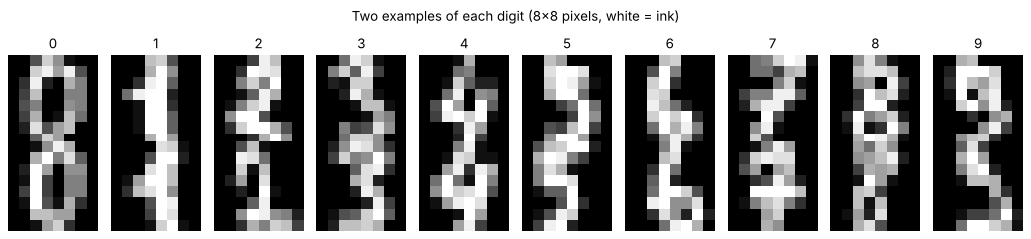

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for digit in range(10):
    examples = df[df["label"] == digit].head(2)
    for row in range(2):
        image = examples.iloc[row][pixel_cols].to_numpy().reshape(8, 8)
        axes[row, digit].imshow(image, cmap="gray", vmin=0, vmax=16)
        axes[row, digit].set_title(str(digit) if row == 0 else "")
        axes[row, digit].axis("off")
plt.suptitle("Two examples of each digit (8x8 pixels, white = ink)")
plt.tight_layout()

In [5]:
# Print one image as numbers: an image is just a grid of numbers
print("Label:", df.loc[0, "label"])
print(df.loc[0, pixel_cols].to_numpy().reshape(8, 8))

Label: 0
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


Fewest: 174  Most: 183


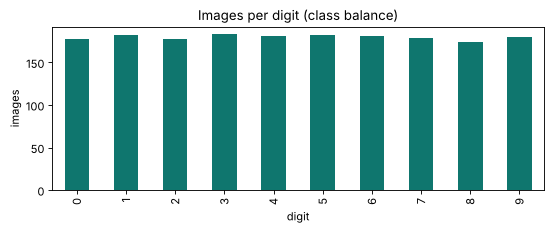

In [6]:
counts = df["label"].value_counts().sort_index()
counts.plot.bar(figsize=(7, 3), color="#0f766e", title="Images per digit (class balance)")
plt.xlabel("digit"); plt.ylabel("images")
plt.tight_layout()
print("Fewest:", counts.min(), " Most:", counts.max())

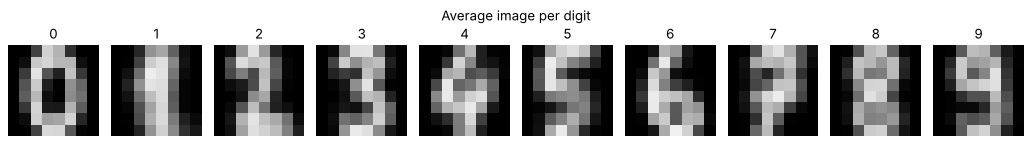

In [7]:
# The "average" image of every digit shows the typical shape the model will learn
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for digit in range(10):
    mean_image = df[df["label"] == digit][pixel_cols].mean().to_numpy().reshape(8, 8)
    axes[digit].imshow(mean_image, cmap="gray", vmin=0, vmax=16)
    axes[digit].set_title(str(digit)); axes[digit].axis("off")
plt.suptitle("Average image per digit")
plt.tight_layout()

**What to notice:**
- All ten digits have about the same number of images (between 174 and 183), so the classes are **balanced** and
  accuracy is a fair headline metric.
- The digits are **large and centred**: they fill almost the whole 8×8 box. A drawing from a browser canvas will not
  automatically look like this — remember this for section 8.
- 8×8 is very low resolution. Some digits (for example 1, 7 and 9, or 3 and 8) can look alike even to a person.

## 3. Features, target, scaling and split

- **Features `X`**: the 64 pixel values. **Target `y`**: the digit.
- **Scaling:** neural networks train best when inputs are small numbers. We divide by 16 so every pixel is between
  0 and 1. We use `to_model_input()` from `backend/preprocess.py`, so the API scales in exactly the same way.
  (Dividing by a fixed number learns nothing from the data, so it cannot leak test information.)
- **Stratified split:** 80% train, 20% test, with the same share of each digit in both parts.

In [8]:
X = to_model_input(df[pixel_cols].to_numpy())   # shape (1797, 64), values 0-1
y = df["label"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Pixel range after scaling:", X.min(), "to", X.max())
print("Test images per digit:", np.bincount(y_test))

Train: (1437, 64)  Test: (360, 64)
Pixel range after scaling: 0.0 to 1.0
Test images per digit: [36 36 35 37 36 37 36 36 35 36]


## 4. Baselines

- **Most-frequent baseline:** always guesses the most common digit. With 10 balanced classes this gets about 10%.
- **Logistic regression:** a simple linear model on the 64 pixels. It is a strong, fast baseline; a neural network
  must beat it to be worth the extra complexity.

In [9]:
results = []

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results.append({"model": "Baseline (most frequent)", "test_accuracy": accuracy_score(y_test, dummy.predict(X_test))})

logreg = LogisticRegression(max_iter=2000).fit(X_train, y_train)
results.append({"model": "Logistic Regression", "test_accuracy": accuracy_score(y_test, logreg.predict(X_test))})

pd.DataFrame(results).set_index("model").round(3)

,test_accuracy
model,
Baseline (most frequent),0.100
Logistic Regression,0.956


## 5. A neural network with scikit-learn (`MLPClassifier`)

An MLP (multi-layer perceptron) is the dense neural network from Module 05:

```
64 inputs ──▶ hidden layer: 64 neurons, ReLU ──▶ output layer: 10 neurons, softmax ──▶ probability of each digit
```

- `hidden_layer_sizes=(64,)`: one hidden layer with 64 neurons.
- `activation="relu"`: the hidden layer uses ReLU. The output uses softmax automatically for multi-class problems.
- `solver="adam"`, `learning_rate_init=0.01`: the Adam optimiser (same idea as in Keras).
- `alpha=1e-3`: L2 regularisation, a small penalty on big weights to reduce overfitting.
- `max_iter=300`: at most 300 passes (epochs) over the training data.

This model trains in seconds without TensorFlow, so it is the **verified fallback model** the API always has.

In [10]:
mlp = MLPClassifier(hidden_layer_sizes=(64,), activation="relu", solver="adam", learning_rate_init=0.01,
                    alpha=1e-3, max_iter=300, random_state=RANDOM_STATE)
mlp.fit(X_train, y_train)

mlp_test_acc = accuracy_score(y_test, mlp.predict(X_test))
mlp_train_acc = accuracy_score(y_train, mlp.predict(X_train))
results.append({"model": "MLP neural network (scikit-learn)", "test_accuracy": mlp_test_acc})
print(f"Epochs run: {mlp.n_iter_}")
print(f"Train accuracy: {mlp_train_acc:.3f}   Test accuracy: {mlp_test_acc:.3f}")
print(f"Weights: {mlp.coefs_[0].shape} (input->hidden) and {mlp.coefs_[1].shape} (hidden->output)")

Epochs run: 100
Train accuracy: 1.000   Test accuracy: 0.983
Weights: (64, 64) (input->hidden) and (64, 10) (hidden->output)


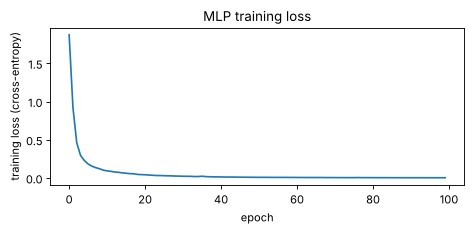

In [11]:
plt.figure(figsize=(6, 3))
plt.plot(mlp.loss_curve_)
plt.xlabel("epoch"); plt.ylabel("training loss (cross-entropy)")
plt.title("MLP training loss")
plt.tight_layout()

The loss drops quickly in the first epochs and then flattens: the network has learned most of what it can.
Training accuracy is higher than test accuracy — the usual small gap between data the model has seen and data it
has not. The test accuracy is what we report.

### Is the result stable? 5-fold cross-validation on the training set

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in [("Logistic Regression", LogisticRegression(max_iter=2000)),
                    ("MLP neural network (scikit-learn)", mlp)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({"model": name, "CV accuracy mean": scores.mean(), "CV accuracy std": scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_results

,CV accuracy mean,CV accuracy std
model,,
Logistic Regression,0.965,0.007
MLP neural network (scikit-learn),0.975,0.010


In [13]:
results_table = pd.DataFrame(results).set_index("model").round(3)
results_table

,test_accuracy
model,
Baseline (most frequent),0.100
Logistic Regression,0.956
MLP neural network (scikit-learn),0.983


**Reading the tables:** both real models are far above the 10% guessing baseline, and the MLP neural network beats
logistic regression on the test set and in cross-validation. In cross-validation the gap is smaller (about one
percentage point, similar to the std), so the honest summary is: the neural network is better, but logistic
regression is already a strong model on these simple images.

## 6. Error analysis: which digits get confused?

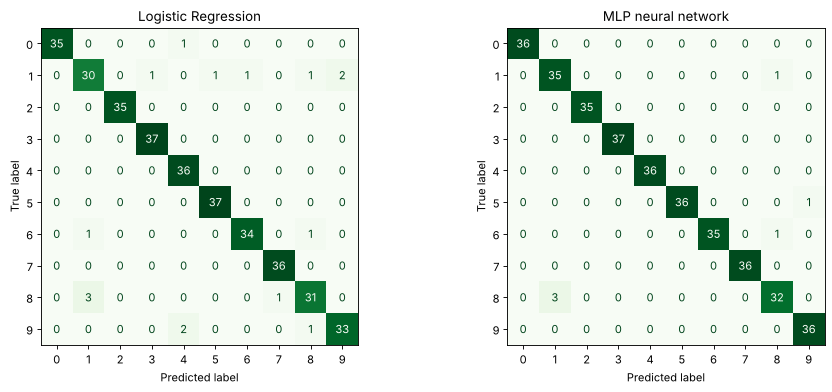

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, [("Logistic Regression", logreg), ("MLP neural network", mlp)]):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, colorbar=False, cmap="Greens")
    ax.set_title(name)
plt.tight_layout()

In [15]:
print(classification_report(y_test, mlp.predict(X_test), digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.921     0.972     0.946        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     0.973     0.986        37
           6      1.000     0.972     0.986        36
           7      1.000     1.000     1.000        36
           8      0.941     0.914     0.928        35
           9      0.973     1.000     0.986        36

    accuracy                          0.983       360
   macro avg      0.984     0.983     0.983       360
weighted avg      0.984     0.983     0.983       360



Wrong predictions: 6 out of 360


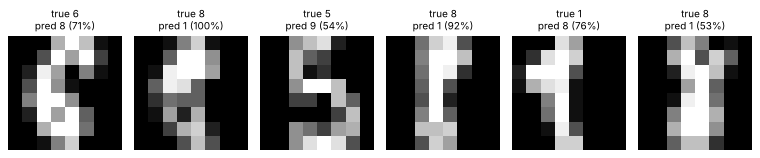

In [16]:
# Which test images does the MLP get wrong?
test_pred = mlp.predict(X_test)
test_proba = mlp.predict_proba(X_test)
wrong = np.where(test_pred != y_test)[0]
print("Wrong predictions:", len(wrong), "out of", len(y_test))

fig, axes = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2.2))
axes = np.atleast_1d(axes)
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"true {y_test[i]}\npred {test_pred[i]} ({test_proba[i].max():.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout()

In [17]:
# How confident is the model when it is right vs wrong?
confidence = test_proba.max(axis=1)
print(f"Average confidence when right: {confidence[test_pred == y_test].mean():.2f}")
print(f"Average confidence when wrong: {confidence[test_pred != y_test].mean():.2f}")

Average confidence when right: 0.99
Average confidence when wrong: 0.74


**What to notice:** the confusion matrices are almost perfectly diagonal. Logistic regression makes more mistakes
(count the numbers off the diagonal in the left matrix); the MLP makes only 6 mistakes on 360 test images, and 4 of them are between
**8 and 1** (the classification report shows the lowest scores for those two digits). At 8×8 a thin, squashed 8 and
a 1 with a base can look very similar — several of the misclassified images are hard even for a person.
The model is also **less confident when it is wrong** — that is why the app shows the full probability bars, not just
the winning digit.

## 7. Deep learning with TensorFlow / Keras (Module 06)

The next cells build the same kind of network in Keras, and then a small **CNN** (convolutional neural network)
that looks at the image as a 2D grid instead of a flat list of 64 numbers.

> **These cells start with `# NO-RUN`.** TensorFlow was not available where this notebook was built, so the cells
> were only syntax-checked and have no outputs. They are correct Keras 3 code: install TensorFlow
> (`pip install -r requirements-tf.txt`, Python 3.10–3.12) and run them yourself. The last one saves
> `models/digits_cnn.keras`; when that file exists and TensorFlow is installed, the API uses the CNN automatically.

In [ ]:
# NO-RUN  (needs TensorFlow: pip install -r requirements-tf.txt)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(RANDOM_STATE)   # same starting weights every run
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

In [ ]:
# NO-RUN
# 7a. Dense ANN — the Keras version of the MLP above
ann = keras.Sequential([
    layers.Input(shape=(64,)),                  # 64 pixel values (0-1)
    layers.Dense(64, activation="relu"),        # hidden layer
    layers.Dropout(0.2),                        # randomly switch off 20% of neurons while training (less overfitting)
    layers.Dense(10, activation="softmax"),     # one probability per digit
])
ann.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy",   # labels are plain integers 0-9
            metrics=["accuracy"])
ann.summary()

# Stop when the validation loss has not improved for 15 epochs, and keep the best weights
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
ann_history = ann.fit(X_train, y_train, validation_split=0.15, epochs=300, batch_size=32,
                      callbacks=[early_stop], verbose=0)
ann_loss, ann_acc = ann.evaluate(X_test, y_test, verbose=0)
print(f"Epochs run: {len(ann_history.history['loss'])}   Keras ANN test accuracy: {ann_acc:.3f}")

In [ ]:
# NO-RUN
# Training curves: if validation loss starts rising while training loss keeps falling, the model is overfitting
pd.DataFrame(ann_history.history)[["loss", "val_loss"]].plot(figsize=(6, 3), title="Keras ANN: loss per epoch")
plt.xlabel("epoch")
plt.tight_layout()

In [ ]:
# NO-RUN
# 7b. A small CNN on the 8x8x1 image (height, width, 1 grey channel)
X_train_img = X_train.reshape(-1, 8, 8, 1)
X_test_img = X_test.reshape(-1, 8, 8, 1)

cnn = keras.Sequential([
    layers.Input(shape=(8, 8, 1)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),   # 32 small 3x3 pattern detectors
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),                                      # 8x8 -> 4x4
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),                                      # 4x4 -> 2x2
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
cnn_history = cnn.fit(X_train_img, y_train, validation_split=0.15, epochs=300, batch_size=32,
                      callbacks=[early_stop], verbose=0)
cnn_loss, cnn_acc = cnn.evaluate(X_test_img, y_test, verbose=0)
print(f"Epochs run: {len(cnn_history.history['loss'])}   Keras CNN test accuracy: {cnn_acc:.3f}")

In [ ]:
# NO-RUN
# Confusion matrix for the CNN, then save it for the API
cnn_pred = cnn.predict(X_test_img, verbose=0).argmax(axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, cnn_pred, colorbar=False, cmap="Greens")
plt.title("Keras CNN")
plt.tight_layout()

os.makedirs("models", exist_ok=True)
cnn.save("models/digits_cnn.keras")                 # Keras 3 native format (one file)
reloaded_cnn = keras.models.load_model("models/digits_cnn.keras")
assert np.allclose(reloaded_cnn.predict(X_test_img[:5], verbose=0), cnn.predict(X_test_img[:5], verbose=0), atol=1e-5)
print("Saved models/digits_cnn.keras and reloaded it. Keras test accuracy — ANN:", round(ann_acc, 3),
      " CNN:", round(cnn_acc, 3), " (compare with the scikit-learn table above)")

**When you run these cells:** compare the Keras ANN and CNN accuracy with the scikit-learn MLP. On only 1,797 tiny
8×8 images, do not expect the CNN to win by much — CNNs shine on bigger images such as 28×28 MNIST (see README
"Ideas to extend"). The numbers differ slightly between computers because of random initialisation.

## 8. From a browser drawing to the model's 8×8 input

In the app, the user draws on a **280×280** canvas with a thick white pen on black. The browser shrinks it to
28×28 and sends it as a 2D list of numbers 0–255. The model, however, was trained on **8×8 images with values 0–16
where the digit fills the box**. `image_to_8x8()` in `backend/preprocess.py` converts one into the other:

1. invert the image if the background is bright (dark digit on light paper),
2. cut out the box around the ink (this centres the digit and removes empty space),
3. pad the box to a square so the digit is not stretched,
4. average the pixels into an 8×8 grid,
5. rescale so the strongest cell is 16.

We cannot draw with a mouse inside this notebook, so the function below "draws" digits from a few straight lines and
arcs with a thick pen, just like the canvas does.

In [18]:
def draw_digit(strokes, size=280, pen_width=22):
    """Draw strokes on a black size x size canvas with a round white pen (values 0-255).

    strokes: list of strokes; each stroke is a list of (x, y) points between 0 and 1.
    """
    rows, cols = np.mgrid[0:size, 0:size]
    canvas = np.zeros((size, size))
    for stroke in strokes:
        points = [(x * size, y * size) for x, y in stroke]
        for (x0, y0), (x1, y1) in zip(points[:-1], points[1:]):
            dx, dy = x1 - x0, y1 - y0
            t = np.clip(((cols - x0) * dx + (rows - y0) * dy) / max(dx * dx + dy * dy, 1e-9), 0, 1)
            distance = np.hypot(cols - (x0 + t * dx), rows - (y0 + t * dy))  # distance to the line segment
            canvas[distance <= pen_width / 2] = 255
    return canvas


def arc(cx, cy, rx, ry, start=0, end=360, n=40):
    """Points on an ellipse (angles in degrees, 0 = right, 90 = down)."""
    a = np.radians(np.linspace(start, end, n))
    return list(zip(cx + rx * np.cos(a), cy + ry * np.sin(a)))


# One simple "hand-drawn" version of every digit
DRAWN = {
    0: [arc(.5, .5, .2, .3)],
    1: [[(.4, .3), (.52, .2), (.52, .8)]],
    2: [arc(.5, .35, .18, .15, 180, 380) + [(.32, .8), (.7, .8)]],
    3: [arc(.48, .35, .17, .14, 200, 450), arc(.48, .64, .19, .16, 270, 520)],
    4: [[(.55, .2), (.3, .6), (.72, .6)], [(.6, .4), (.6, .82)]],
    5: [[(.68, .2), (.38, .2), (.35, .45)], arc(.5, .62, .18, .18, 220, 500)],
    6: [[(.6, .2), (.38, .5)], arc(.5, .64, .16, .16)],
    7: [[(.3, .2), (.7, .2), (.42, .8)]],
    8: [arc(.5, .33, .15, .13), arc(.5, .65, .18, .17)],
    9: [arc(.5, .36, .16, .15), [(.66, .36), (.6, .8)]],
}

[[ 0 12 16 16 16 16 12  0]
 [ 0  0  0  0  0 11  6  0]
 [ 0  0  0  0  2 15  0  0]
 [ 0  0  0  0 10  7  0  0]
 [ 0  0  0  1 15  1  0  0]
 [ 0  0  0  8  8  0  0  0]
 [ 0  0  1 15  1  0  0  0]
 [ 0  0  6  9  0  0  0  0]]
Predicted digit: 7 with probability 0.71


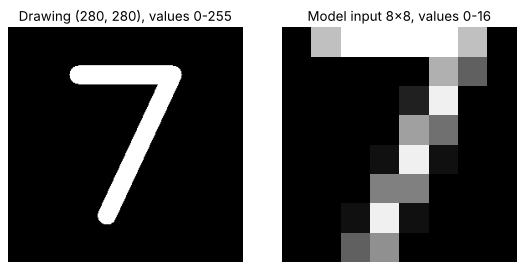

In [19]:
# Step by step for one drawn "7"
canvas = draw_digit(DRAWN[7])
small = image_to_8x8(canvas)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(canvas, cmap="gray"); axes[0].set_title(f"Drawing {canvas.shape}, values 0-255")
axes[1].imshow(small, cmap="gray", vmin=0, vmax=16); axes[1].set_title("Model input 8x8, values 0-16")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
print(small)
proba = mlp.predict_proba(to_model_input(small))[0]
print("Predicted digit:", proba.argmax(), f"with probability {proba.max():.2f}")

Correct on 80% of the 10 synthetic drawings


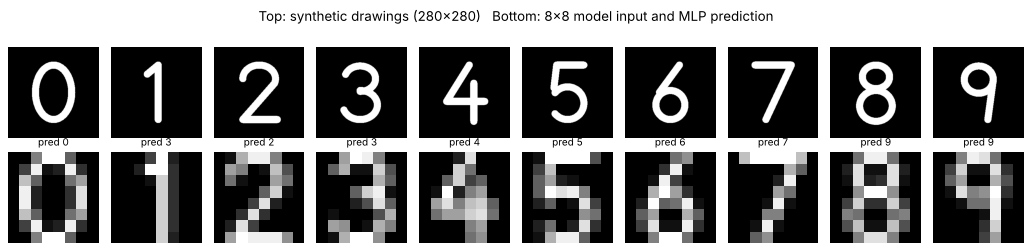

drawn,0,1,2,3,4,5,6,7,8,9
predicted,0.0,3.0,2.0,3.00,4.0,5.0,6.00,7.00,9.0,9.0
probability,1.0,1.0,1.0,0.68,1.0,1.0,0.67,0.71,0.6,1.0


In [20]:
# All ten drawn digits through the same pipeline the API uses
drawn_rows = []
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for digit, strokes in DRAWN.items():
    canvas = draw_digit(strokes)
    small = image_to_8x8(canvas)
    proba = mlp.predict_proba(to_model_input(small))[0]
    drawn_rows.append({"drawn": digit, "predicted": int(proba.argmax()), "probability": round(float(proba.max()), 2)})
    axes[0, digit].imshow(canvas, cmap="gray"); axes[0, digit].axis("off")
    axes[1, digit].imshow(small, cmap="gray", vmin=0, vmax=16); axes[1, digit].axis("off")
    axes[1, digit].set_title(f"pred {proba.argmax()}", fontsize=9)
plt.suptitle("Top: synthetic drawings (280x280)   Bottom: 8x8 model input and MLP prediction")
plt.tight_layout()

drawn_results = pd.DataFrame(drawn_rows).set_index("drawn")
drawn_accuracy = float((drawn_results["predicted"] == drawn_results.index).mean())
print(f"Correct on {drawn_accuracy:.0%} of the 10 synthetic drawings")
drawn_results.T

### What happens when drawings differ from the training style?

The pipeline above crops and centres the drawing. Below we try the same digits in ways a real user might draw them,
and also show what happens if we **skip the cropping step** and simply shrink the whole canvas to 8×8.

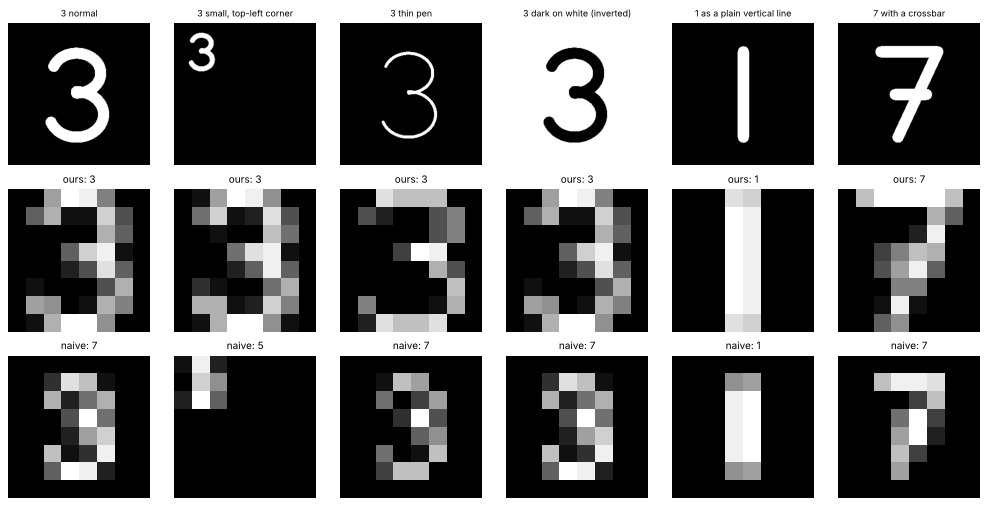

,true,with crop+centre,naive resize
drawing,,,
3 normal,3,3 (68%),7 (77%)
"3 small, top-left corner",3,3 (79%),5 (88%)
3 thin pen,3,3 (92%),7 (95%)
3 dark on white (inverted),3,3 (68%),7 (77%)
1 as a plain vertical line,1,1 (100%),1 (99%)
7 with a crossbar,7,7 (99%),7 (100%)


In [21]:
def naive_8x8(canvas):
    """Shrink the WHOLE canvas to 8x8 without cropping (what you might write first)."""
    size = canvas.shape[0] // 8
    small = canvas[:size * 8, :size * 8].reshape(8, size, 8, size).mean(axis=(1, 3))
    return np.rint(small / max(small.max(), 1e-9) * 16)


def shrink(strokes, scale, dx=0.0, dy=0.0):
    """Make a drawing smaller and move it (a small digit drawn in a corner)."""
    return [[(x * scale + dx, y * scale + dy) for x, y in stroke] for stroke in strokes]


variants = {
    "3 normal": (3, draw_digit(DRAWN[3])),
    "3 small, top-left corner": (3, draw_digit(shrink(DRAWN[3], 0.4), pen_width=10)),
    "3 thin pen": (3, draw_digit(DRAWN[3], pen_width=6)),
    "3 dark on white (inverted)": (3, 255 - draw_digit(DRAWN[3])),
    "1 as a plain vertical line": (1, draw_digit([[(.5, .2), (.5, .8)]])),
    "7 with a crossbar": (7, draw_digit(DRAWN[7] + [[(.4, .5), (.62, .5)]])),
}

rows = []
fig, axes = plt.subplots(3, len(variants), figsize=(2.1 * len(variants), 6.4))
for col, (name, (true_digit, canvas)) in enumerate(variants.items()):
    ours = image_to_8x8(canvas)
    naive = naive_8x8(canvas if canvas[0, 0] < 128 else 255 - canvas)
    p_ours = mlp.predict_proba(to_model_input(ours))[0]
    p_naive = mlp.predict_proba(to_model_input(naive))[0]
    rows.append({"drawing": name, "true": true_digit,
                 "with crop+centre": f"{p_ours.argmax()} ({p_ours.max():.0%})",
                 "naive resize": f"{p_naive.argmax()} ({p_naive.max():.0%})"})
    axes[0, col].imshow(canvas, cmap="gray"); axes[0, col].set_title(name, fontsize=8)
    axes[1, col].imshow(ours, cmap="gray", vmin=0, vmax=16); axes[1, col].set_title(f"ours: {p_ours.argmax()}", fontsize=9)
    axes[2, col].imshow(naive, cmap="gray", vmin=0, vmax=16); axes[2, col].set_title(f"naive: {p_naive.argmax()}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
pd.DataFrame(rows).set_index("drawing")

**Reading the results (section 8):**
- The MLP recognised **8 of the 10** synthetic drawings. The two misses are honest examples of style differences:
  our "1" has a flag at the top and is predicted as **3** — with almost 100% probability, a *confident* mistake — and
  our "8" is predicted as **9** (60%). The correct 3, 6 and 7 get only about 70% probability, much lower than the 99%
  average on correctly predicted test images. A high probability is not a guarantee, and the model is generally
  less sure about drawings than about the scans it was trained on.
- A **plain vertical line** is recognised as 1, while the 1 with a flag is not: the model learned the style of the
  43 writers in the dataset, not every way a person can write a 1.
- **Cropping and centring matter.** With the naive resize, every version of the 3 is wrong (predicted 7, or 5 for the
  small one in the corner), because the digit does not fill the 8×8 box like the training digits do. With
  `image_to_8x8()` all four 3s are correct, including the small one, the thin one and the inverted one.
- So the preprocessing step is part of the model: the API must use exactly the same function, which is why it lives
  in `backend/preprocess.py` and is imported here.

## 9. Save the model and the information the API needs

- `models/digits_mlp_sklearn.joblib` — the trained MLP (the API's fallback model; always available).
- `models/model_info.json` — input format, class names and the honest test metrics, for the API's `/api/health`.
- `models/digits_cnn.keras` — only created when you run the Keras cells in section 7.

In [22]:
os.makedirs("models", exist_ok=True)
joblib.dump(mlp, "models/digits_mlp_sklearn.joblib")

model_info = {
    "fallback_model": "MLPClassifier (scikit-learn), 64-64-10",
    "fallback_file": "digits_mlp_sklearn.joblib",
    "keras_file": "digits_cnn.keras",
    "classes": list(range(10)),
    "image_size": 8,
    "pixel_max": 16,
    "input_scaling": "pixel / 16 (see backend/preprocess.py)",
    "test_accuracy": {name: round(float(acc), 3) for name, acc in results_table["test_accuracy"].items()},
    "cv_accuracy_mlp": round(float(cv_results.loc["MLP neural network (scikit-learn)", "CV accuracy mean"]), 3),
    "synthetic_drawings_correct": f"{int(drawn_accuracy * 10)}/10",
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)
print(json.dumps(model_info["test_accuracy"], indent=2))
print(sorted(os.listdir("models")))

{
  "Baseline (most frequent)": 0.1,
  "Logistic Regression": 0.956,
  "MLP neural network (scikit-learn)": 0.983
}
['digits_mlp_sklearn.joblib', 'model_info.json']


In [23]:
# Reload from disk exactly as the API will, and check predictions match
reloaded = joblib.load("models/digits_mlp_sklearn.joblib")
assert np.allclose(reloaded.predict_proba(X_test[:5]), mlp.predict_proba(X_test[:5]))
print("Reloaded model gives identical probabilities.")

Reloaded model gives identical probabilities.


## 10. Limitations and possible improvements

- **8×8 is tiny.** A whole digit is only 64 numbers, so details such as a small loop or a crossbar can disappear.
  Some pairs (1/7, 3/9, 5/9, 8/9) are easy to confuse at this size.
- **Drawings are not scans.** The training digits were written with a pen on paper by 43 people and shrunk from
  32×32. Mouse and finger drawings have different stroke widths, shapes and positions. The crop-and-centre step
  helps a lot (section 8), but real users will still see more mistakes than the test accuracy suggests.
- **The test accuracy is measured on the same kind of images as training**, not on browser drawings. A real
  project would collect a few hundred drawings from the app, label them and measure accuracy on those.
- **The model always answers.** Even a scribble or a letter gets a digit. The probability bars help, and a simple
  rule such as "show *not sure* when the top probability is below 50%" would be a good addition.
- **Improvements to try:** train on MNIST (28×28, 70,000 images) with the CNN, add data augmentation
  (small rotations/shifts with `keras.layers.RandomRotation` / `RandomTranslation`), and fine-tune on drawings
  collected from the app.

**Next step:** start the Flask API in `backend/` (see the project README). It loads the files saved above and uses
`backend/preprocess.py` for every drawing it receives.